# Tahap 5 KDD - Evaluasi

Menghitung metrik pada data uji: accuracy, balanced accuracy, precision/recall/F1 per kelas dan macro, Cohen's kappa, ROC-AUC, log loss, confusion matrix, kurva ROC/PR, dan analisis salah prediksi.

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path

HERE = Path.cwd().resolve()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config as C

In [2]:
from src.evaluate import run_evaluation

metrics, cm, predictions = run_evaluation(verbose=True)
metrics

              precision    recall  f1-score   support

        baik      0.839     0.684     0.754        38
      sedang      0.538     0.538     0.538        26
         aus      0.776     0.905     0.835        42

    accuracy                          0.736       106
   macro avg      0.718     0.709     0.709       106
weighted avg      0.740     0.736     0.733       106



28 citra salah prediksi -> reports/tables/salah_prediksi.csv
Metrik test: {'model': 'SVM', 'feature_set': 'D_Lengkap', 'n_features': 63, 'n_test': 106, 'accuracy': 0.7358, 'balanced_accuracy': 0.7091, 'precision_macro': 0.7176, 'recall_macro': 0.7091, 'f1_macro': 0.7091, 'cohen_kappa': 0.5948, 'recall_baik': 0.6842, 'recall_sedang': 0.5385, 'recall_aus': 0.9048, 'roc_auc_ovr_macro': 0.8531, 'log_loss': 0.6853}


{'model': 'SVM',
 'feature_set': 'D_Lengkap',
 'n_features': 63,
 'n_test': 106,
 'accuracy': 0.7358,
 'balanced_accuracy': 0.7091,
 'precision_macro': 0.7176,
 'recall_macro': 0.7091,
 'f1_macro': 0.7091,
 'cohen_kappa': 0.5948,
 'recall_baik': 0.6842,
 'recall_sedang': 0.5385,
 'recall_aus': 0.9048,
 'roc_auc_ovr_macro': 0.8531,
 'log_loss': 0.6853}

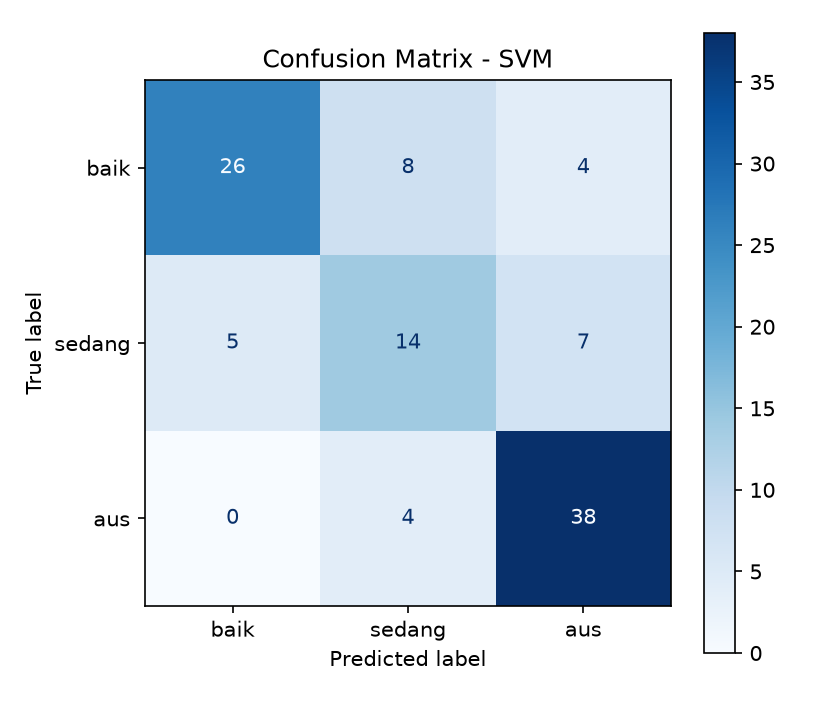

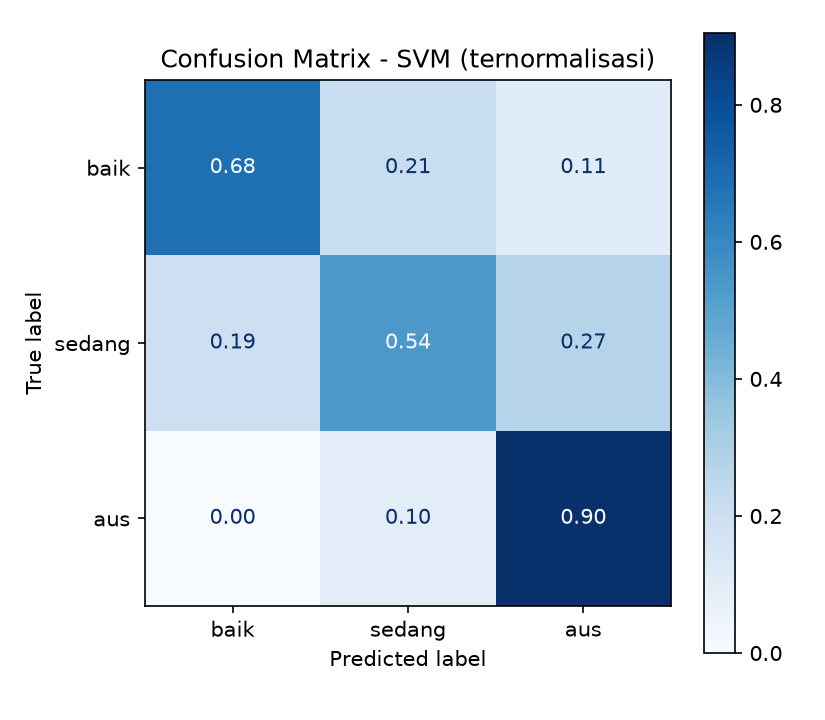

In [3]:
from IPython.display import Image, display

display(Image(filename=str(C.FIG_DIR / "confusion_matrix.png")))
display(Image(filename=str(C.FIG_DIR / "confusion_matrix_normalized.png")))

In [4]:
import pandas as pd

err = pd.read_csv(C.TAB_DIR / "salah_prediksi.csv")
print("Jumlah salah prediksi:", len(err))
err.head(20)

Jumlah salah prediksi: 28


,file,label,prediksi,proba_prediksi
0,ban_bagus_104.png,baik,sedang,0.6677
1,ban_bagus_133.png,baik,sedang,0.8961
2,ban_bagus_15.png,baik,aus,0.3784
3,ban_bagus_179.png,baik,sedang,0.4923
4,ban_bagus_197.png,baik,aus,0.8666
5,ban_bagus_198.png,baik,sedang,0.7742
6,ban_bagus_30.png,baik,aus,0.4522
7,ban_bagus_35.png,baik,sedang,0.4615
8,ban_bagus_52.png,baik,aus,0.9093
9,ban_bagus_54.png,baik,sedang,0.6751


perbandingan_model.png


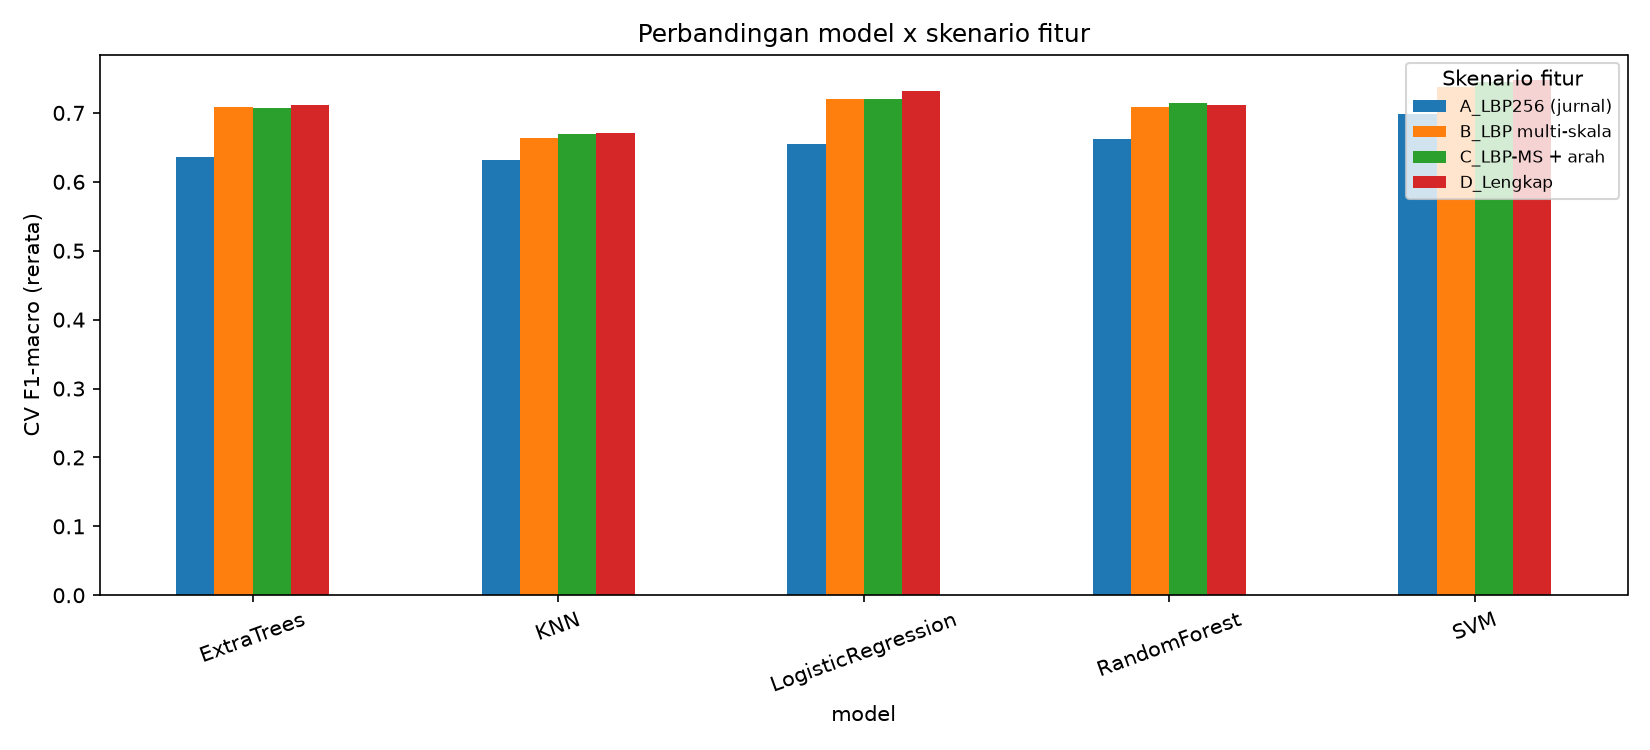

roc_curve.png


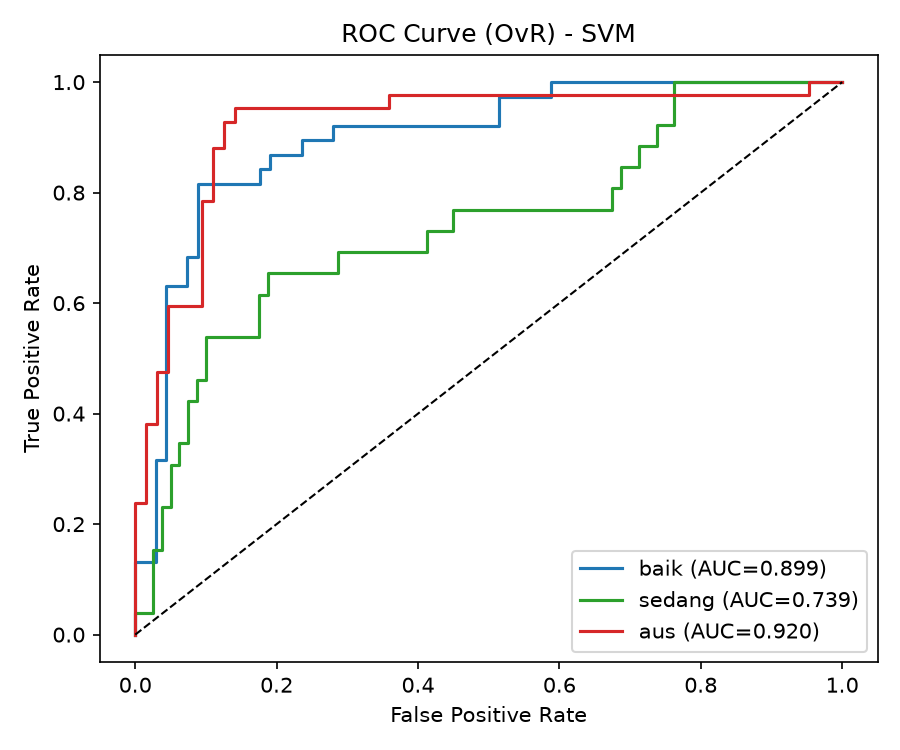

precision_recall_curve.png


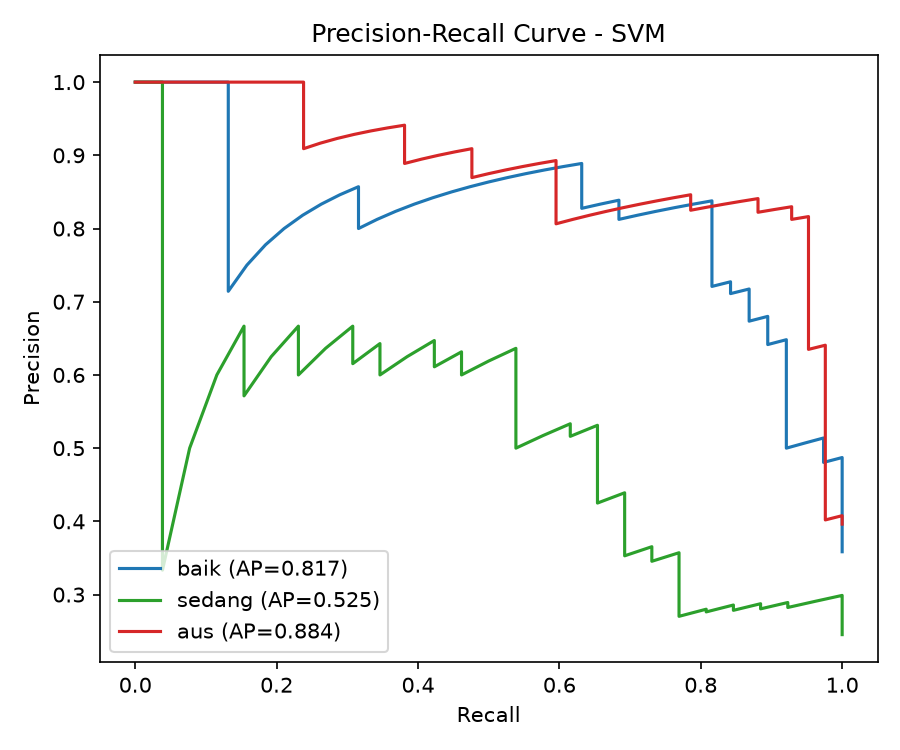

learning_curve.png


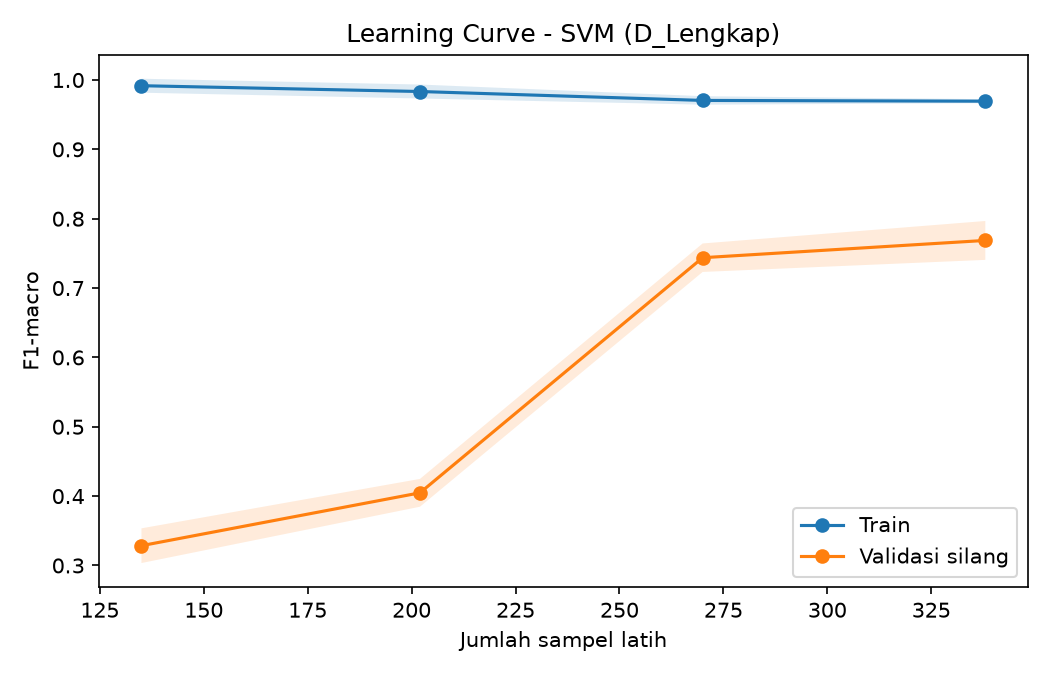

In [5]:
from IPython.display import Image, display

for name in ["perbandingan_model.png", "roc_curve.png", "precision_recall_curve.png", "learning_curve.png"]:
    p = C.FIG_DIR / name
    if p.exists():
        print(name)
        display(Image(filename=str(p)))